In [161]:
import numpy as np
import sympy as sp
from scipy.integrate import quad
import matplotlib.pyplot as plt
import math
import time

In [162]:
def genelist(a, b, n):
    return np.linspace(a, b, int(n))

a = input('digite o extremo inferior: ');
b = input('digite o extremo superior: ');
eps = input('entre a precisao: ');
i =1;

f = @(x) exp(x)-x^2-3;
%f = inline(exp(x)-x^2-3)
if f(a) * f(b)>0
    disp('Sem raizes');
else
    fprintf('iteracao   valor   erro cometido\n');
    while (b-a)>eps
        x=(a+b)/2;
        if f(x)*f(a)<0
            b=x;
        else
            a=x;
        end
        erro = abs((b-a)/b);
        fprintf('%5d %19.5f %19.2e \n', i, x, erro);
        i=i+1;
    end
    fprintf('O valor da raiz eh %8.5f \n', x);
end

In [163]:
import numpy as np

def f(r, rs, M):
    return r + 2 * M * np.log(r / (2 * M) - 1) - rs

def findzero(f, range, tor):
    if not callable(f):
        raise TypeError("O argumento 'f' precisa ser uma função (ex: lambda x: ... ou def ...)")
    
    # Converte o intervalo para floats reais (equivalente ao // Re)
    range_arr = np.array(range, dtype=float)
    # fr = f /@ (range {1 + 10^-15, 1 - 10^-15}) // Re;
    deslocamento = np.array([1.0+1e-15, 1.0-1e-15])
    range_deslocado = range_arr * deslocamento
    fr = np.array([np.real(f(range_deslocado[0])), np.real(f(range_deslocado[1]))])

    # x0 = Mean@range // Re;
    x0 = np.real(np.mean(range_arr))

    # range1 = If[Re[f[x0]*fr[[1]]] > 0, {x0, range[[2]]}, {range[[1]], x0}] // Re;
    if np.real(f(x0) * fr[0]) > 0:
        range1 = np.array([x0, range_arr[1]])
    else:
        range1 = np.array([range_arr[0], x0])

    range1 = np.real(range1)
    # print(f"range1 = {range1}")
    
    # While[Abs@First@Differences@range1 > tor, ...
    while abs(range1[1] - range1[0])>tor:
        x0 = np.real(np.mean(range1))
        if np.real(f(x0) * fr[0])>0:
            range1 = [x0, range1[1]]
        else:
            range1 = [range1[0], x0]

        range1 = np.real(range1)
    return {'x': float(x0)}



In [164]:
# rstar = 25
# M = 1.0
# resultado = findzero(lambda r: f(r, rstar, M), [2 * M + 1e-15, 10000.0], 1e-6)
# print(f"Resultado do findzero: r é aproximadamente {resultado['x']:.6f}")

In [165]:
def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
    av, bv = pertubation_params
    rsmax = 2 * tmax
    rstarlist = genelist(rsv - rsmax/2.0, rsv + rsmax/2.0, numMax)
    
    def findrvalue(rs_target, M):
        #[2 * M + 1e-15, 10000.0] intervalo onde encontrar a raiz, 1e-6 é a tolerância, tendo relação dentro de ln, r/2m-1 >0, portanto r>2m
        return findzero(lambda r: f(r, rs_target, M), [2*M, 10000.0], 1e-12)['x']
    
    hr = float(np.diff(rstarlist[:2])[0])
    print(f"rstarlist[0], rstarlist[1]: {rstarlist[0]}, {rstarlist[1]}"
    )
    print(f"rstarlist[1] - rstarlist[0]: {rstarlist[1] - rstarlist[0]}")
    print(f"hr: {hr}")
    ht =0.5 * hr 

    inicio = time.time()
    rlist0 = np.array([findrvalue(rs, M) for rs in rstarlist], dtype = float)
    tempo_execucao  = time.time() - inicio
    print(f"Tempo de execução para encontrar rlist0: {tempo_execucao:.6f} segundos")

    rlist = rlist0

    def V_potencial(rlist, L, M):
        return (1.0 - 2* M/rlist) * (L*(L+1)/rlist**2 - 6 *M/rlist**3)

    Vv = V_potencial(rlist, L, M)

    ii = 1
    psi0 = np.zeros(len(rlist))
    psi1 = ht * np.exp(-((rstarlist - av)**2) / (2 * (bv**2)))
    length = int((numMax - 1) / 2)
    psi_collect = np.zeros(length)

    inicio_loop = time.time()
    while ii <= length:
        Vv = Vv[1:-1]
        psi2 = -(ht**2) * (
                    (psi0[1:-1] / (ht**2)) 
                    - (2 * psi1[1:-1] / (ht**2)) 
                    + (Vv * psi1[1:-1]) 
                    - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))
                )
        if ii == 1:
            print(f"rstarlist[length - ii]: {rstarlist[length - ii]}")
            print(f"(ht**2): {ht**2}")
            print(f"psi0[length - ii]: {psi0[length - ii]}")
            print(f"psi1[length - ii]: {psi1[length - ii]}")
            print(f"Vv[length - ii]: {Vv[length - ii]}")
            print(f"(psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2): {(psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2)}")
            print(f"psi2[length - ii]: {psi2[length - ii - 1]}")
            print(f"psi2 = -(ht**2) * ((psi0[1:-1] / (ht**2)) - (2 * psi1[1:-1] / (ht**2)) + (Vv * psi1[1:-1]) - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))) --> {psi2[length - ii - 1]} = {-(ht**2)} * {((psi0[length - ii] / (ht**2)) - (2 * psi1[length - ii] / (ht**2)) + (Vv[length - ii] * psi1[length - ii]) - ((psi1[length - ii -1] - 2 * psi1[length - ii] + psi1[length - ii +1]) / (hr**2))) }")
        psi0 = psi1[1:-1]
        psi1 = psi2

        psi_collect[ii-1] = psi1[length - ii]
        ii+=1

    tempo_execucao_loop  = time.time() - inicio_loop
    print(f"Tempo de execução do loop: {tempo_execucao_loop:.6f} segundos")
    return ht, psi_collect


In [166]:
def plotEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))
    plt.plot(t, psi, lw=2)

    t_max = t[-1]
    plt.xticks(np.arange(0, t_max + 1, 100))
    plt.xlabel("t")
    plt.ylabel(r"$\Psi$")
    plt.grid(True)
    plt.title(title)
    plt.show()


def plotLogEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

rstarlist[0], rstarlist[1]: -1975.0, -1974.8
rstarlist[1] - rstarlist[0]: 0.20000000000004547
hr: 0.20000000000004547
Tempo de execução para encontrar rlist0: 12.550756 segundos
rstarlist[length - ii]: 24.800000000000182
(ht**2): 0.010000000000004547
psi0[length - ii]: 0.0
psi1[length - ii]: 0.003404745473461513
Vv[length - ii]: 0.012205561935945792
(psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2): 0.004908585020288135
psi2[length - ii]: 0.006858154427681391
psi2 = -(ht**2) * ((psi0[1:-1] / (ht**2)) - (2 * psi1[1:-1] / (ht**2)) + (Vv * psi1[1:-1]) - ((psi1[:-2] - 2 * psi1[1:-1] + psi1[2:]) / (hr**2))) --> 0.006858154427681391 = -0.010000000000004547 * -0.6858161228805286
Tempo de execução do loop: 0.887297 segundos


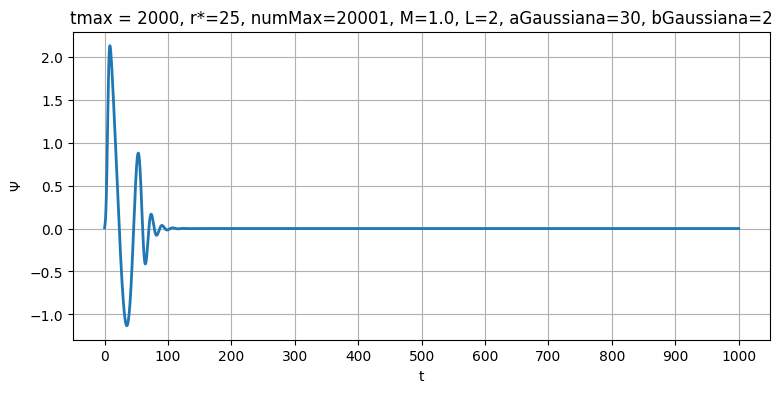

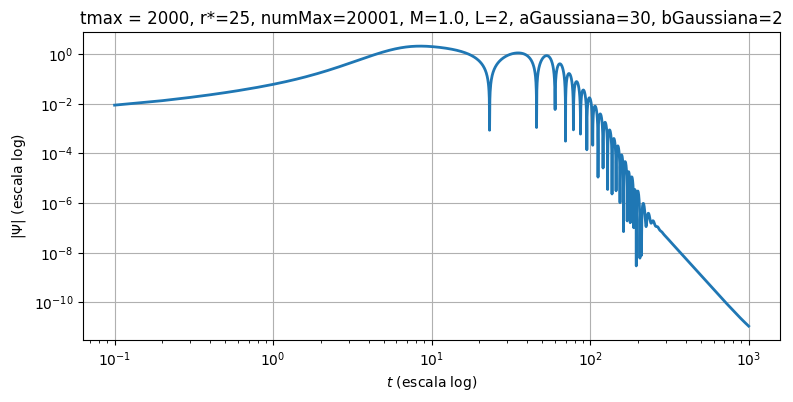

In [167]:
# def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
test1 = getEvo(2000, 25, 20001, 1.0, 2, (30, 2))
plotEvolution(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2, aGaussiana=30, bGaussiana=2"
)
plotLogEvolution(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2, aGaussiana=30, bGaussiana=2"
)

In [168]:
def plotLogEvolutionmod(test, title=""):

    ht, psi = test
    print(f"len(psi): {len(psi)}")
    print(f"ht: {ht}")

    t = ht * np.arange(3000, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.loglog(
        t,
        np.abs(psi[2999:]),
        lw=2
    )

    plt.xlabel(r"$t$ (escala log)")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

len(psi): 10000
ht: 0.10000000000002274


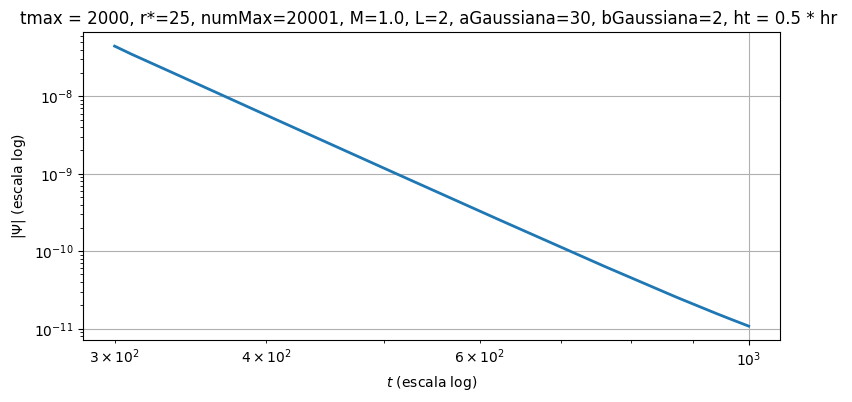

In [169]:
plotLogEvolutionmod(
    test1,
    "tmax = 2000, r*=25, numMax=20001, M=1.0, L=2, aGaussiana=30, bGaussiana=2, ht = 0.5 * hr "
)

In [170]:
import numpy as np

ht, psi = test1

# Tempo correspondente
t = ht * np.arange(1, len(psi) + 1)

# Intervalo desejado
inicio = 3000
fim = 9001      # o último índice (9000) é incluído

t_fit = t[inicio:fim]
psi_fit = np.abs(psi[inicio:fim])

# Evita log(0)
mask = psi_fit > 0

x = np.log10(t_fit[mask])
y = np.log10(psi_fit[mask])

# Ajuste linear
coef = np.polyfit(x, y, 1)

slope = coef[0]
intercept = coef[1]

print(f"Inclinação = {slope:.6f}")
print(f"Intercepto = {intercept:.6f}")

Inclinação = -6.994985
Intercepto = 9.958488


If a static I,-pole field is present outside the star, prior to the onset of collapse,
the field will fall off as t
'"'". If there is no field
initially outside the star, but an l-pole perturbation develops during the collapse process, it will
fall off as t^(2l+3) a.t la.rge time